In [1]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.0 MB/s eta 0:00:00


In [2]:
!pip install xgboost catboost scikit-learn seaborn matplotlib imbalanced-learn


✅ Dataset loaded: (395, 9)
✅ After feature engineering: (392, 36)

=== CLASSIFICATION ===
Classes before rare-class filter: ['Excellent', 'Good', 'Heavily Polluted', 'Lightly Polluted', 'Moderately Polluted', 'Severely Polluted', '严重的污染']
⚠️ Dropping rare classes with <2 samples: ['严重的污染']

Logistic Regression - Accuracy: 0.9494, Weighted F1: 0.9429
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.86      0.86      0.86         7
           2       0.94      0.89      0.91        18
           3       1.00      1.00      1.00        13
           4       1.00      1.00      1.00        11
           5       0.94      1.00      0.97        29

    accuracy                           0.95        79
   macro avg       0.79      0.79      0.79        79
weighted avg       0.94      0.95      0.94        79



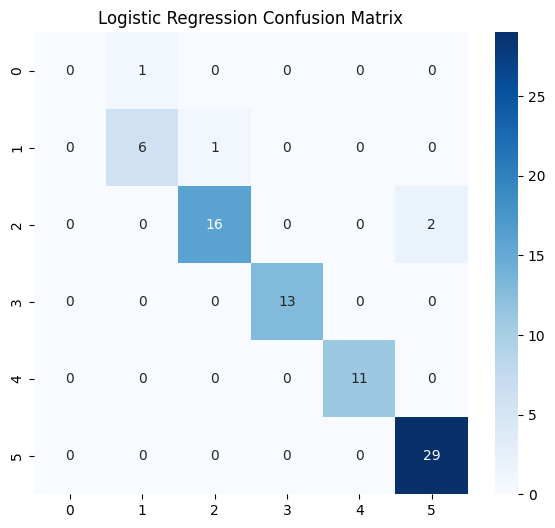


XGBoost (tuned) - Accuracy: 0.9747, Weighted F1: 0.9697
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.78      1.00      0.88         7
           2       1.00      1.00      1.00        18
           3       1.00      0.92      0.96        13
           4       1.00      1.00      1.00        11
           5       1.00      1.00      1.00        29

    accuracy                           0.97        79
   macro avg       0.80      0.82      0.81        79
weighted avg       0.97      0.97      0.97        79



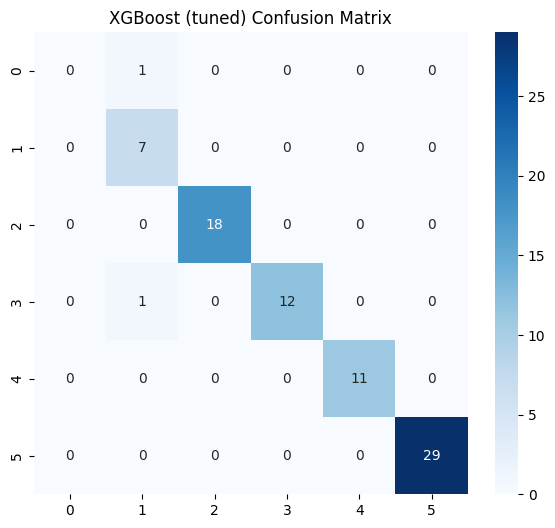


CatBoost (tuned) - Accuracy: 0.9747, Weighted F1: 0.9697
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.78      1.00      0.88         7
           2       1.00      1.00      1.00        18
           3       1.00      0.92      0.96        13
           4       1.00      1.00      1.00        11
           5       1.00      1.00      1.00        29

    accuracy                           0.97        79
   macro avg       0.80      0.82      0.81        79
weighted avg       0.97      0.97      0.97        79



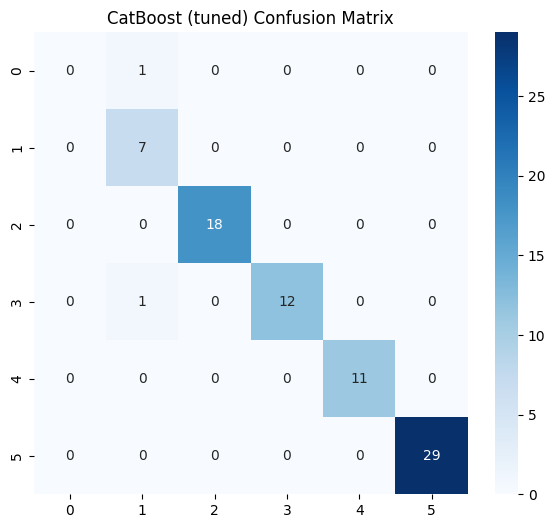


Stacking Ensemble - Accuracy: 0.9747, Weighted F1: 0.9697
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.78      1.00      0.88         7
           2       1.00      1.00      1.00        18
           3       1.00      0.92      0.96        13
           4       1.00      1.00      1.00        11
           5       1.00      1.00      1.00        29

    accuracy                           0.97        79
   macro avg       0.80      0.82      0.81        79
weighted avg       0.97      0.97      0.97        79



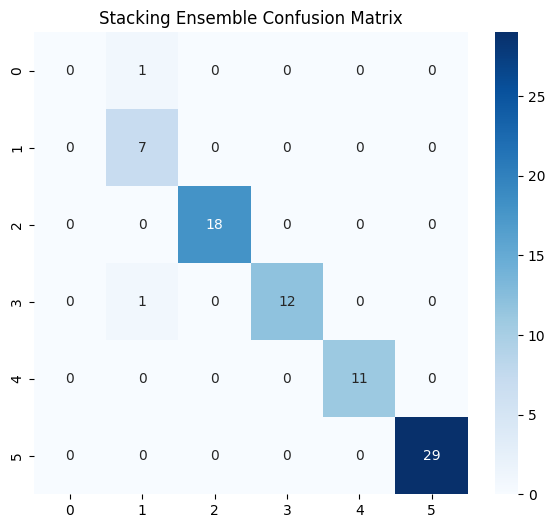

Stacking CV weighted-F1 mean/std: 0.9875620955944857 0.017156618667977533

=== REGRESSION ===

Linear Regression - R²: 1.0000, RMSE: 0.0000, MAE: 0.0000


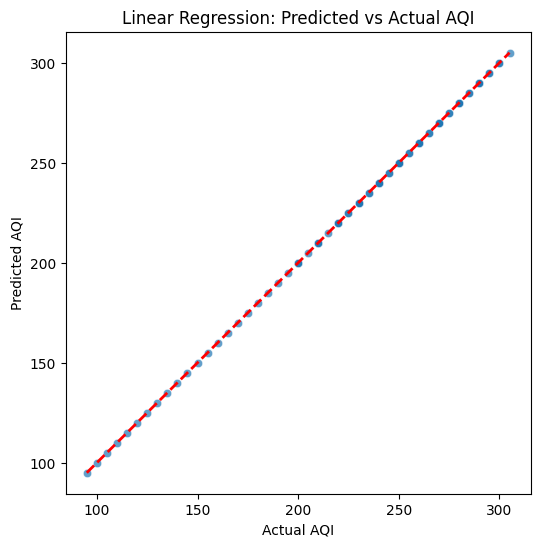


XGBoost - R²: 1.0000, RMSE: 0.0234, MAE: 0.0079


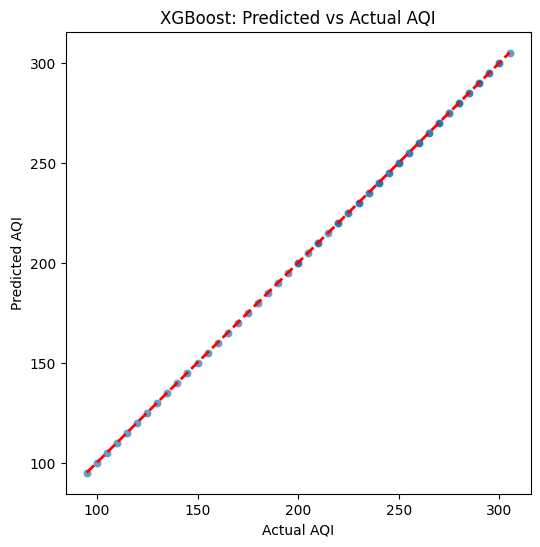


CatBoost - R²: 0.9955, RMSE: 3.7515, MAE: 2.5467


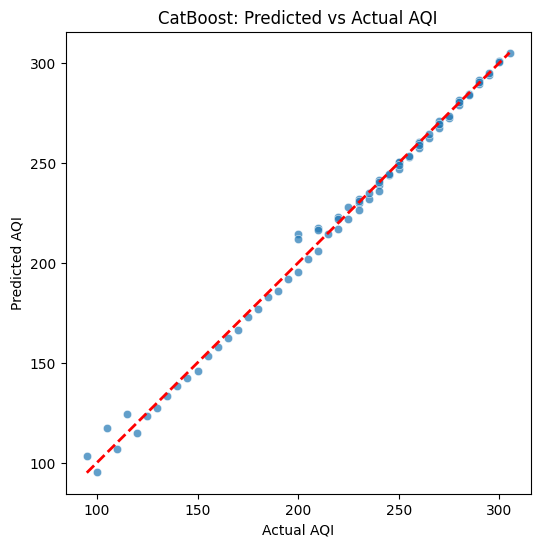


Stacking Ensemble - R²: 1.0000, RMSE: 0.1963, MAE: 0.1315


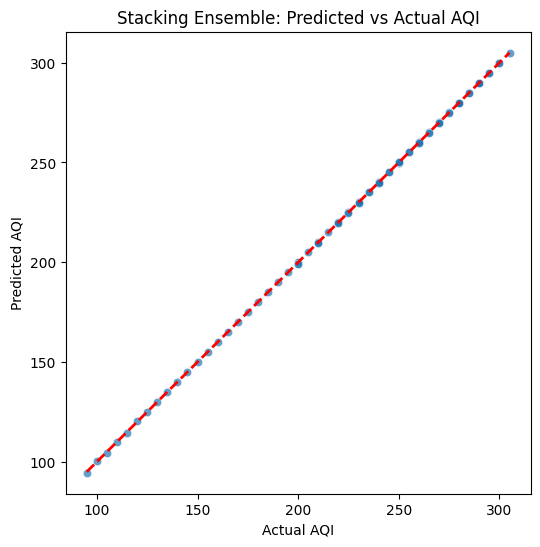

Stacking Ensemble CV R² mean/std: 0.9999059928252173 7.142505688420956e-05

✅ Full pipeline finished! Logistic Regression now included and working.


In [3]:
# full_aqi_pipeline_fixed.py
# Install deps first (if not already):
# !pip install xgboost catboost scikit-learn seaborn matplotlib imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import StackingClassifier, StackingRegressor
from sklearn.metrics import (
    classification_report, accuracy_score, f1_score, confusion_matrix,
    r2_score, mean_squared_error, mean_absolute_error
)
from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

# =====================================================
# 1. LOAD + PREPROCESS
# =====================================================
file_path = "/content/dataset.csv"   # change path if needed
cols = ['date', 'aqi', 'class', 'pm2.5', 'pm10', 'so2', 'co', 'no2', 'o3']
df = pd.read_csv(file_path, on_bad_lines="skip", names=cols, header=0)

df['date'] = pd.to_datetime(df['date'], format='%Y%m%d', errors='coerce')
df = df.dropna(subset=['date']).reset_index(drop=True)

# Translate Chinese labels if needed
translation_map = {
    "优": "Excellent", "良": "Good",
    "轻度污染": "Lightly Polluted", "中度污染": "Moderately Polluted",
    "重度污染": "Heavily Polluted", "严重污染": "Severely Polluted"
}
df['class'] = df['class'].map(lambda x: translation_map.get(x, x))

df = df.dropna().reset_index(drop=True)
print("✅ Dataset loaded:", df.shape)

# =====================================================
# 2. FEATURE ENGINEERING
# =====================================================
df['month'] = df['date'].dt.month
df['dayofyear'] = df['date'].dt.dayofyear
df['weekday'] = df['date'].dt.weekday
df = df.sort_values('date').reset_index(drop=True)

pollutants = ['pm2.5', 'pm10', 'so2', 'co', 'no2', 'o3']
for p in pollutants:
    for lag in [1, 2, 3]:
        df[f'{p}_lag{lag}'] = df[p].shift(lag)
    df[f'{p}_roll3'] = df[p].rolling(window=3, min_periods=1).mean()

df = df.dropna().reset_index(drop=True)
print("✅ After feature engineering:", df.shape)

# =====================================================
# 3. CLASSIFICATION
# =====================================================
print("\n=== CLASSIFICATION ===")
X_cls = df.drop(columns=['date', 'aqi', 'class'])
y_cls = df['class']

# Encode target
le = LabelEncoder()
y_cls_enc = le.fit_transform(y_cls)
print("Classes before rare-class filter:", list(le.classes_))

# Drop rare classes with <2 samples
class_counts = pd.Series(y_cls_enc).value_counts()
rare_classes = class_counts[class_counts < 2].index
if len(rare_classes) > 0:
    print("⚠️ Dropping rare classes with <2 samples:", [le.classes_[c] for c in rare_classes])
    mask = ~pd.Series(y_cls_enc).isin(rare_classes)
    X_cls = X_cls[mask]
    y_cls_enc = y_cls_enc[mask]

# Train/test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls_enc, test_size=0.2, stratify=y_cls_enc, random_state=42
)

scaler_cls = MinMaxScaler()
X_train_c = scaler_cls.fit_transform(X_train_c)
X_test_c = scaler_cls.transform(X_test_c)

# Define models
log_reg = LogisticRegression(max_iter=2000, random_state=42)

xgb_cls = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss',
                        use_label_encoder=False, random_state=42)
xgb_params = {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}
cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_gs = GridSearchCV(xgb_cls, xgb_params, cv=cv_cls, scoring='f1_weighted', n_jobs=-1)
xgb_gs.fit(X_train_c, y_train_c)
xgb_best = xgb_gs.best_estimator_

cat_cls = CatBoostClassifier(verbose=False, random_state=42)
cat_params = {'iterations': [100, 200], 'learning_rate': [0.05, 0.1], 'depth': [4, 6]}
cat_gs = GridSearchCV(cat_cls, cat_params, cv=cv_cls, scoring='f1_weighted', n_jobs=-1)
cat_gs.fit(X_train_c, y_train_c)
cat_best = cat_gs.best_estimator_

stack_cls = StackingClassifier(
    estimators=[('xgb', xgb_best), ('cat', cat_best), ('log', log_reg)],
    final_estimator=LogisticRegression(), cv=cv_cls, n_jobs=-1
)
stack_cls.fit(X_train_c, y_train_c)

# Helper function
def eval_classification(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f"\n{name} - Accuracy: {acc:.4f}, Weighted F1: {f1:.4f}")
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{name} Confusion Matrix")
    plt.show()

# ✅ Fit Logistic Regression separately before evaluation
log_reg.fit(X_train_c, y_train_c)

# Evaluate all models
eval_classification(log_reg, X_test_c, y_test_c, "Logistic Regression")
eval_classification(xgb_best, X_test_c, y_test_c, "XGBoost (tuned)")
eval_classification(cat_best, X_test_c, y_test_c, "CatBoost (tuned)")
eval_classification(stack_cls, X_test_c, y_test_c, "Stacking Ensemble")

cv_scores_cls = cross_val_score(stack_cls, X_cls, y_cls_enc, cv=cv_cls, scoring='f1_weighted')
print("Stacking CV weighted-F1 mean/std:", cv_scores_cls.mean(), cv_scores_cls.std())

# =====================================================
# 4. REGRESSION
# =====================================================
print("\n=== REGRESSION ===")
X_reg = df.drop(columns=['date', 'class', 'aqi'])
y_reg = df['aqi']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, shuffle=False, random_state=42
)

scaler_r = MinMaxScaler()
X_train_r = scaler_r.fit_transform(X_train_r)
X_test_r = scaler_r.transform(X_test_r)

linreg = LinearRegression()
xgb_reg = XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05,
                       subsample=0.8, colsample_bytree=0.8, random_state=42)
cat_reg = CatBoostRegressor(iterations=300, depth=6, learning_rate=0.05,
                            loss_function='RMSE', verbose=False, random_state=42)
stack_reg = StackingRegressor(
    estimators=[('xgb', xgb_reg), ('cat', cat_reg)],
    final_estimator=LinearRegression(), n_jobs=-1
)

def eval_regression(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_test, y_pred)
    print(f"\n{name} - R²: {r2:.4f}, RMSE: {rmse:.4f}, MAE: {mae:.4f}")
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             'r--', lw=2)
    plt.xlabel("Actual AQI"); plt.ylabel("Predicted AQI")
    plt.title(f"{name}: Predicted vs Actual AQI")
    plt.show()

for name, model in {
    "Linear Regression": linreg,
    "XGBoost": xgb_reg,
    "CatBoost": cat_reg,
    "Stacking Ensemble": stack_reg
}.items():
    model.fit(X_train_r, y_train_r)
    eval_regression(model, X_test_r, y_test_r, name)

# CV for regression
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_reg = cross_val_score(stack_reg, scaler_r.transform(X_reg), y_reg, cv=kf, scoring='r2')
print("Stacking Ensemble CV R² mean/std:", cv_scores_reg.mean(), cv_scores_reg.std())

print("\n✅ Full pipeline finished! Logistic Regression now included and working.")
